# **Data Cleaning**

## Objectives

* Check the dataset for unreadable images
* Investigate duplications and augmented 
* Prepare a split between 3 parts 
* prepare the image data for model development

## Inputs

* Original images from data/raw/cherry-leaves
* 2104 healthy and 2104 mildewy images
* Images are 256 pixels by 256

## Outputs

* Dataset quality check results 
* Assessment of augmented and duplicate images
* Clean Train, test and validation datasets 
* Documented image preparation decisions

## Additional Comments

* Original images will remain unchanged 
* Aim to achieve 97% accuracy



---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [16]:
from pathlib import Path
import os

PROJECT_ROOT = Path("/workspaces/FInal-Project-01")

os.chdir(PROJECT_ROOT)

print("Current working directory:", Path.cwd())

Current working directory: /workspaces/FInal-Project-01


In [4]:
from pathlib import Path
from collections import Counter

import pandas as pd
from PIL import Image, UnidentifiedImageError

dataset_path = Path("data/raw/cherry-leaves/cherry-leaves")

class_folders = {
    "healthy": dataset_path / "healthy",
    "powdery_mildew": dataset_path / "powdery_mildew"
}

for category, folder in class_folders.items():
    print(f"{category}: {folder.exists()}")

healthy: True
powdery_mildew: True


In [5]:
supported_extensions = {".jpg", ".jpeg", ".png", ".webp", ".JPG"}

corrupted_images = []
image_counts = {}

for category, folder in class_folders.items():
    image_files = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in supported_extensions
    ]

    image_counts[category] = len(image_files)

    for image_path in image_files:
        try:
            with Image.open(image_path) as image:
                image.verify()
        except (OSError, ValueError, UnidentifiedImageError):
            corrupted_images.append(str(image_path))

print("Image counts:", image_counts)
print("Corrupted images found:", len(corrupted_images))

Image counts: {'healthy': 2104, 'powdery_mildew': 2104}
Corrupted images found: 0


In [6]:
augmentation_counts = {}

for category, folder in class_folders.items():
    filenames = [
        file.stem.lower()
        for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in supported_extensions
    ]

    augmentation_counts[category] = {
        "flipLR": sum("_fliplr" in name for name in filenames),
        "flipTB": sum("_fliptb" in name for name in filenames),
        "180deg": sum("_180deg" in name for name in filenames),
    }

pd.DataFrame(augmentation_counts).T

,flipLR,flipTB,180deg
healthy,0,654,655
powdery_mildew,1052,0,0


In [7]:
import re
from collections import defaultdict

def get_source_image_id(filename):
    stem = Path(filename).stem

    # Remove the unique identifier before ___
    source_name = stem.split("___", 1)[-1]

    # Remove known augmentation suffixes
    source_name = re.sub(
        r"_(180deg|flipLR|flipTB)$",
        "",
        source_name,
        flags=re.IGNORECASE
    )

    return source_name


image_groups = defaultdict(list)

for category, folder in class_folders.items():
    for image_path in folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in supported_extensions:
            source_id = get_source_image_id(image_path.name)
            image_groups[(category, source_id)].append(image_path)

print("Total images:", sum(len(group) for group in image_groups.values()))
print("Unique source-image groups:", len(image_groups))
print("Groups containing multiple images:",
      sum(len(group) > 1 for group in image_groups.values()))

Total images: 4208
Unique source-image groups: 1847
Groups containing multiple images: 1707


In [8]:
multiple_image_groups = {
    key: images
    for key, images in image_groups.items()
    if len(images) > 1
}

for (category, source_id), images in list(multiple_image_groups.items())[:5]:
    print(f"\nCategory: {category}")
    print(f"Source image: {source_id}")
    print(f"Number of versions: {len(images)}")

    for image_path in images:
        print(" -", image_path.name)


Category: healthy
Source image: JR_HL 3977
Number of versions: 3
 - e4a4adf6-5ad5-420f-bab7-64812af0ac2d___JR_HL 3977_180deg.JPG
 - e4a4adf6-5ad5-420f-bab7-64812af0ac2d___JR_HL 3977_flipTB.JPG
 - e4a4adf6-5ad5-420f-bab7-64812af0ac2d___JR_HL 3977.JPG

Category: healthy
Source image: JR_HL 4268
Number of versions: 3
 - 68f0e459-0938-4988-862f-893afb413d57___JR_HL 4268_flipTB.JPG
 - 68f0e459-0938-4988-862f-893afb413d57___JR_HL 4268_180deg.JPG
 - 68f0e459-0938-4988-862f-893afb413d57___JR_HL 4268.JPG

Category: healthy
Source image: JR_HL 9861
Number of versions: 3
 - 9f57292a-576b-4ae8-a71a-cdaf42bcd6b7___JR_HL 9861_180deg.JPG
 - 9f57292a-576b-4ae8-a71a-cdaf42bcd6b7___JR_HL 9861.JPG
 - 9f57292a-576b-4ae8-a71a-cdaf42bcd6b7___JR_HL 9861_flipTB.JPG

Category: healthy
Source image: JR_HL 9580
Number of versions: 3
 - 484ade57-5dd0-4764-b379-5a0e684afd81___JR_HL 9580.JPG
 - 484ade57-5dd0-4764-b379-5a0e684afd81___JR_HL 9580_180deg.JPG
 - 484ade57-5dd0-4764-b379-5a0e684afd81___JR_HL 9580_flipTB.

In [9]:
from sklearn.model_selection import train_test_split

train_groups = []
validation_groups = []
test_groups = []

for category in class_folders.keys():

    category_groups = [
        group_key
        for group_key in image_groups.keys()
        if group_key[0] == category
    ]

    print(f"{category}: {len(category_groups)} source groups")

    train, remaining = train_test_split(
        category_groups,
        test_size=0.30,
        random_state=42
    )

    validation, test = train_test_split(
        remaining,
        test_size=0.50,
        random_state=42
    )

    train_groups.extend(train)
    validation_groups.extend(validation)
    test_groups.extend(test)

print("\nTraining groups:", len(train_groups))
print("Validation groups:", len(validation_groups))
print("Test groups:", len(test_groups))

healthy: 795 source groups
powdery_mildew: 1052 source groups

Training groups: 1292
Validation groups: 277
Test groups: 278


In [ ]:
def count_split_images(groups):
    counts = {"healthy": 0, "powdery_mildew": 0}

    for group in groups:
        category = group[0]
        counts[category] += len(image_groups[group])

    return counts


split_summary = {}

for split_name, groups in {
    "Training": train_groups,
    "Validation": validation_groups,
    "Test": test_groups
}.items():
    counts = count_split_images(groups)

    split_summary[split_name] = {
        "Healthy": counts["healthy"],
        "Powdery Mildew": counts["powdery_mildew"],
        "Total": sum(counts.values())
    }

import pandas as pd

pd.DataFrame(split_summary).T

,Healthy,Powdery Mildew,Total
Training,1464,1472,2936
Validation,310,316,626
Test,330,316,646


## Dataset Split Distribution

The following chart shows the number of images assigned to the training, validation and test datasets.

The dataset was split approximately 70% for training, 15% for validation and 15% for testing.

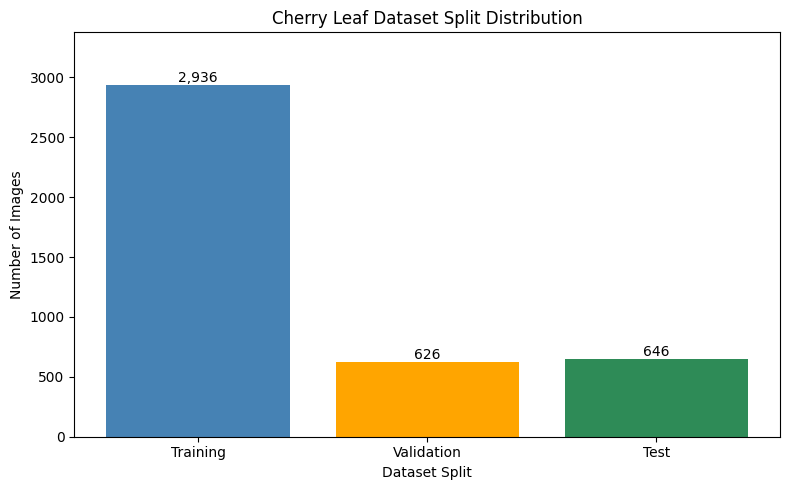

In [15]:
import matplotlib.pyplot as plt

split_names = ["Training", "Validation", "Test"]
split_counts = [
    split_summary[name]["Total"]
    for name in split_names
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_names,
    split_counts,
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Cherry Leaf Dataset Split Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 25,
        f"{int(height):,}",
        ha="center"
    )

plt.ylim(0, max(split_counts) * 1.15)
plt.tight_layout()
plt.show()

### Interpretation

The training dataset contains 2,936 images, representing approximately
70% of the total dataset.

The validation dataset contains 626 images and the test dataset
contains 646 images, representing approximately 15% each.

The training dataset provides the images used to learn patterns
associated with healthy and powdery mildew leaves.

The validation dataset is used to monitor model performance during
training, while the test dataset is reserved for the final evaluation
of the trained CNN.

Known augmented versions of source images were grouped during splitting
to reduce the risk of data leakage between datasets.

In [11]:
train_set = set(train_groups)
validation_set = set(validation_groups)
test_set = set(test_groups)

print("Train / validation overlap:", len(train_set & validation_set))
print("Train / test overlap:", len(train_set & test_set))
print("Validation / test overlap:", len(validation_set & test_set))

assert not (train_set & validation_set)
assert not (train_set & test_set)
assert not (validation_set & test_set)

print("No source-image groups overlap between splits.")

Train / validation overlap: 0
Train / test overlap: 0
Validation / test overlap: 0
No source-image groups overlap between splits.


---

In [19]:
from pathlib import Path
import shutil

processed_path = PROJECT_ROOT / "data" / "processed"

split_groups = {
    "train": train_groups,
    "validation": validation_groups,
    "test": test_groups
}

for split_name, groups in split_groups.items():

    for category in class_folders:
        destination = processed_path / split_name / category
        destination.mkdir(parents=True, exist_ok=True)

    for group_key in groups:
        category = group_key[0]
        destination = processed_path / split_name / category

        for image_path in image_groups[group_key]:
            destination_file = destination / image_path.name

            if not destination_file.exists():
                shutil.copy2(image_path, destination_file)

print("Processed dataset created successfully!")

Processed dataset created successfully!


In [14]:
for split_name in split_groups:
    print(f"\n{split_name.upper()}")

    for category in class_folders:
        folder = processed_path / split_name / category

        image_count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in supported_extensions
        )

        print(f"{category}: {image_count}")


TRAIN
healthy: 1464
powdery_mildew: 1472

VALIDATION
healthy: 310
powdery_mildew: 316

TEST
healthy: 330
powdery_mildew: 316


In [17]:
from pathlib import Path

processed_path = PROJECT_ROOT / "data" / "processed"

expected_filenames = {
    split_name: {
        category: {
            image_path.name
            for group_key in groups
            if group_key[0] == category
            for image_path in image_groups[group_key]
        }
        for category in class_folders
    }
    for split_name, groups in {
        "train": train_groups,
        "validation": validation_groups,
        "test": test_groups
    }.items()
}

for split_name, categories in expected_filenames.items():
    for category, expected in categories.items():
        folder = processed_path / split_name / category

        existing = {
            file.name
            for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in supported_extensions
        } if folder.exists() else set()

        print(
            f"{split_name}/{category}: "
            f"{len(expected)} expected, "
            f"{len(existing - expected)} unexpected, "
            f"{len(expected - existing)} missing"
        )

train/healthy: 1464 expected, 0 unexpected, 0 missing
train/powdery_mildew: 1472 expected, 0 unexpected, 0 missing
validation/healthy: 310 expected, 0 unexpected, 0 missing
validation/powdery_mildew: 316 expected, 0 unexpected, 0 missing
test/healthy: 330 expected, 0 unexpected, 0 missing
test/powdery_mildew: 316 expected, 0 unexpected, 0 missing


### Data Preparation Findings

- The dataset contains 4,208 images across two balanced categories.
- No corrupted images were identified.
- Filename analysis identified 1,847 source-image groups.
- Augmented versions of the same source image were assigned to the same dataset split.
- The dataset was divided into training (2,936 images), validation (626 images), and testing (646 images).
- No source-image group overlap was detected between the three splits.
- The original images were preserved, and processed copies were saved separately.

These steps reduce the risk of data leakage and prepare the dataset for model training.

---

## Conclusions and Next Steps

### Conclusions

- The original dataset contains 4,208 cherry leaf images, with 2,104 images in each category.
- All images passed the file integrity checks.
- Filename analysis identified 1,847 source-image groups.
- Known augmented versions of the same source image were kept within the same dataset split to reduce the risk of data leakage.
- The dataset was divided into:
  - Training: 2,936 images
  - Validation: 626 images
  - Testing: 646 images
- No source-image groups overlap between the training, validation and test datasets.
- The processed dataset was verified to contain no missing or unexpected images.
- Original images were preserved in `data/raw/`, while the prepared datasets were saved in `data/processed/`.

### Next Steps

- Use the training and validation datasets to develop a Convolutional Neural Network (CNN) in Notebook 04.
- Apply image resizing and pixel normalisation as required by the model.
- Monitor training and validation accuracy and loss to assess model performance and overfitting.
- Save the trained model for evaluation and use in the Streamlit dashboard.